# All years combined (2020–2025)

**Method:** each plant's influent concentration is averaged over all years it reported (2020, 2021, 2023, 2024, 2025),
so **every plant counts once**. The distribution is then taken across plants: median = typical plant,
IQR (P25–P75) = middle 50% of plants.

Public WWTPs ≥ 500 m³/day. A value of 0 means "not measured" and is left out.
COD$_{Mn}$ is not included because it exists only for 2020.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"font.family": "Arial", "font.size": 15})

years = [2020, 2021, 2023, 2024, 2025]   # 2022 is not available
params = {   # name: (column, bar width in mg/L, decimals)
    "BOD": ("Influent_Biochemical Oxygen Demand (BOD)", 20,  0),
    "TOC": ("Influent_Total Organic Carbon (TOC)",      10,  0),
    "T-N": ("Influent_Total Nitrogen (T-N)",            5,   1),
    "T-P": ("Influent_Total Phosphorus (T-P)",          0.5, 1),
}

data = []
for year in years:
    df = pd.read_csv(f"../data/{year}/translated_{year}1231.csv")
    df = df[df["Facility Capacity"] >= 500]   # large plants only
    df["year"] = year
    data.append(df)
data = pd.concat(data)
data["plant"] = data["Province/Metro City"] + " | " + data["District (Gu/Gun)"].fillna("") + " | " + data["Facility Name"]

## Step 1: one average value per plant

In [2]:
plant_means = {}
for name, (column, _, _) in params.items():
    measured = data[data[column] > 0]
    plant_means[name] = measured.groupby("plant")[column].mean()   # average over the plant's years

pd.DataFrame(plant_means).round(2).head(10)

,BOD,TOC,T-N,T-P
plant,,,,
Busan | Dongnae-gu | Suyeong,176.18,78.75,42.89,4.45
Busan | Gangseo-gu | Noksan,153.68,78.45,34.56,3.26
Busan | Gangseo-gu | Seobu,159.56,78.88,34.75,3.84
Busan | Gijang-gun | Dongbusan,214.55,103.70,39.54,4.52
Busan | Gijang-gun | Gijang,154.22,65.30,31.35,3.79
Busan | Gijang-gun | Ilgwang,259.73,128.32,69.12,7.14
Busan | Gijang-gun | Jeonggwan,227.48,109.28,55.49,5.86
Busan | Gijang-gun | Munoseong,172.26,78.65,36.91,5.20
Busan | Haeundae-gu | Dongbu,133.88,68.58,31.65,3.36


## Step 2: distribution across plants

In [3]:
rows = []
for name, values in plant_means.items():
    rows.append({"parameter": name, "plants": len(values),
                 "median": values.median(), "P25": values.quantile(0.25), "P75": values.quantile(0.75),
                 "mean": values.mean(), "SD": values.std(), "min": values.min(), "max": values.max()})
combined = pd.DataFrame(rows).set_index("parameter").round(2)
Path("../tables").mkdir(exist_ok=True)
combined.to_csv("../tables/combined_all_years.csv", encoding="utf-8-sig")
combined

,plants,median,P25,P75,mean,SD,min,max
parameter,,,,,,,,
BOD,737,174.88,134.98,223.80,179.20,61.80,30.46,403.40
TOC,729,83.72,63.77,111.72,87.92,33.17,8.47,197.27
T-N,737,40.15,33.82,47.83,41.39,12.12,8.72,89.81
T-P,737,4.33,3.54,5.14,4.39,1.30,0.63,8.14


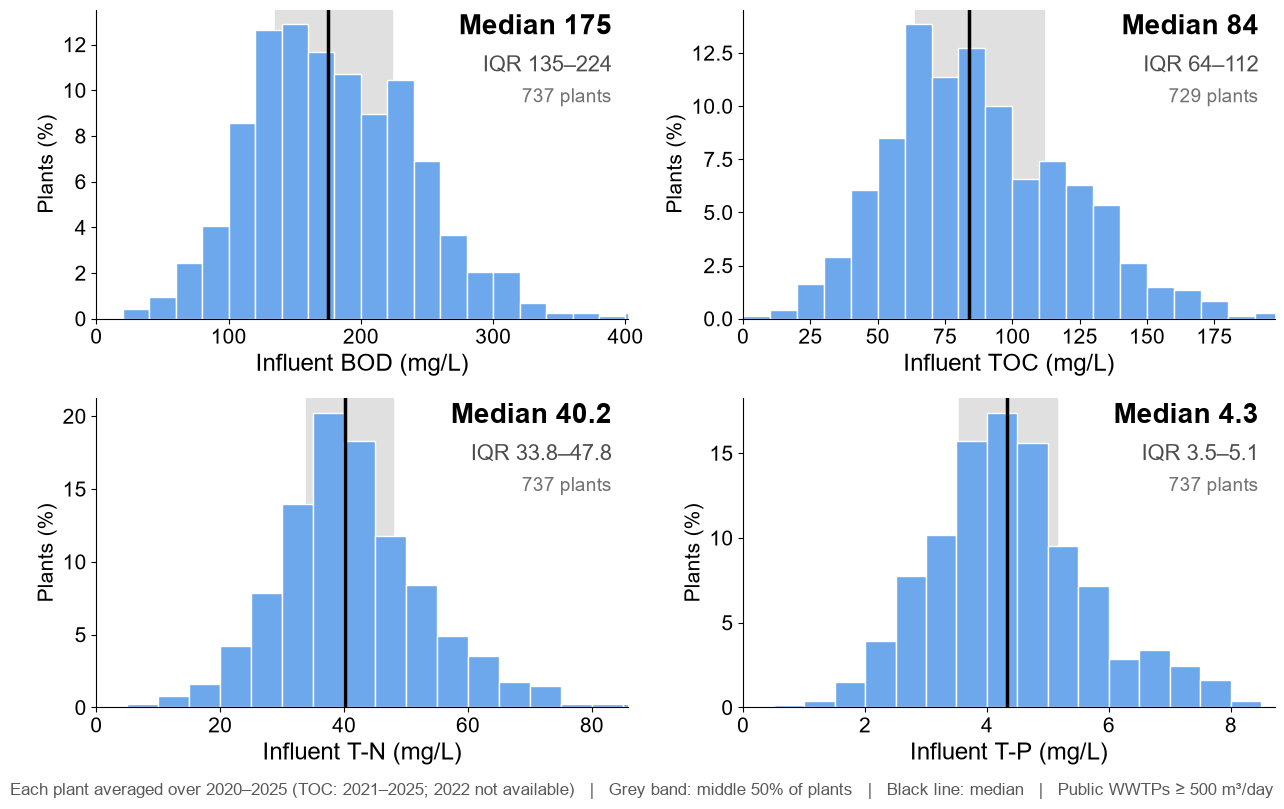

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, (name, (column, width, decimals)) in zip(axes.flat, params.items()):
    values = plant_means[name]
    q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
    bins = np.arange(0, values.max() + width, width)

    ax.axvspan(q1, q3, color="0.88", zorder=0)
    ax.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)),
            color="#6da7ec", edgecolor="white")
    ax.axvline(median, color="black", linewidth=2.5)

    ax.text(0.97, 0.92, f"Median {median:.{decimals}f}", transform=ax.transAxes, ha="right",
            fontsize=20, fontweight="bold")
    ax.text(0.97, 0.80, f"IQR {q1:.{decimals}f}–{q3:.{decimals}f}", transform=ax.transAxes, ha="right",
            fontsize=16, color="0.3")
    ax.text(0.97, 0.70, f"{len(values)} plants", transform=ax.transAxes, ha="right", fontsize=14, color="0.45")

    ax.set_xlim(0, values.quantile(0.995) * 1.1)
    ax.set_xlabel(f"Influent {name} (mg/L)", fontsize=17)
    ax.set_ylabel("Plants (%)")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.text(0.01, -0.01, "Each plant averaged over 2020–2025 (TOC: 2021–2025; 2022 not available)   |   "
         "Grey band: middle 50% of plants   |   Black line: median   |   Public WWTPs ≥ 500 m³/day",
         fontsize=12, color="0.35")
fig.tight_layout()
Path("../figures/slides").mkdir(parents=True, exist_ok=True)
fig.savefig("../figures/slides/combined_all_years.png", dpi=300, bbox_inches="tight")
plt.show()